In [1]:
#imagenumber = 31

In [1]:
#!git clone https://github.com/ultralytics/yolov5  # clone
%cd yolov5
#!pip install -qr requirements.txt comet_ml  # install

import torch
import utils
display = utils.notebook_init()  # checks
import torch
import utils
from IPython.display import Image  # for displaying images
import os 
import random
import shutil
from sklearn.model_selection import train_test_split
import xml.etree.ElementTree as ET
from xml.dom import minidom
from tqdm import tqdm
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import pathlib
temp = pathlib.PosixPath
pathlib.PosixPath = pathlib.WindowsPath # this load_learn adjusts code for windows delete if using linix or mac 
import cv2
import sys
from fastai.vision.all import *
import matplotlib.pyplot as plt
random.seed(108)


YOLOv5  v7.0-269-gad97dc6 Python-3.11.5 torch-2.1.2+cu118 CPU


Setup complete  (24 CPUs, 31.1 GB RAM, 412.1/1862.1 GB disk)


In [2]:
print("imagenumber I'm up to is the following")
print(imagenumber)

print(f"The loop took {elapsed_time:.4f} seconds to execute.")
from fastai.vision.all import *
def label_func(fn): return path/"labels"/f"{fn.stem}_P{fn.suffix}"

imagenumber I'm up to is the following


NameError: name 'imagenumber' is not defined

In [6]:
# Get a list of files in the directory
file_list = os.listdir(rawimagesetdir)
# Sort the list of files
sorted_file_list = sorted(file_list)


In [7]:

image_path = rawimagesetdir+sorted_file_list[imagenumber]
print(sorted_file_list[imagenumber])
# load image in 
image = Image.open(image_path)
imagedraw = cv2.imread(str(image_path))


Zn_AL_ZnSO4_test23-07-05-18-16-20.png


In [2]:
# clear folders for past processing

# Specify the directory path
save_directory = mainpipelocation+"cropdump/"  # Replace with the actual folder path

# List all files in the directory
file_list = os.listdir(save_directory)

# Iterate through the files and delete them
for filename in file_list:
    file_path = os.path.join(save_directory, filename)
    
    # Check if the path is a file (not a directory) and delete it
    if os.path.isfile(file_path):
        os.remove(file_path)

print(f"All files in {save_directory} have been deleted.")

#try:
# Specify the directory path

runs = here+"\yolov5\\runs"  # Replace with the actual folder path

# List all files and directories in the directory
entries = os.listdir(runs)

# Iterate through the entries and delete them
for entry in entries:
    entry_path = os.path.join(runs, entry)

    if os.path.isfile(entry_path):
        # Delete files
        os.remove(entry_path)
    elif os.path.isdir(entry_path):
        # Delete directories and their contents
        shutil.rmtree(entry_path)  # Use shutil.rmtree() to delete non-empty directories

print(f"All files and directories in {runs} have been deleted.")
#except:
#    print("failed to delete stuff")


All files in /notebooks/mainpipeline/cropdump1/ have been deleted.
All files and directories in /notebooks/mainbody/one/yolov5/runs have been deleted.


In [9]:
# crop images

width, height = image.size

stepsx = (width -640) / 640 * 2 
stepsy = (height-640) / 640 * 2 

x=0 
y=0
it = 1
while (x < stepsx +1) :
    y=0
    while (y<stepsy + 1) : 
        xranges = (0+320*x , 640 + 320*x)  
        yranges = (0+320*y , 640 + 320*y)
        
        crop_box = (xranges[0], yranges[0], xranges[1], yranges[1])
        
        cropped_image = image.crop(crop_box)
        #plt.imshow(cropped_image)
        #plt.axis('on')  # Hide axis labels and ticks
        #plt.show()
        
        # Specify the directory where you want to save the image
        save_directory = mainpipelocation+"cropdump/"
        
        # Specify the filename for the saved image (e.g., "saved_image.jpg")
        filename = "cropimage"+str(it)+".png"

        # Combine the directory and filename to create the full path
        full_path = save_directory + filename
        
        
        
        cropped_image.save(full_path)
        it = it + 1 
        y=y+1
    
    x=x+1





In [9]:
# Use Yolo
!python detect.py --source C:\Users\bowan\Documents\CODING\gelion\processing_images\first_pipe_image_processing\mainpipeline\cropdump\ --weights C:\Users\bowan\Documents\CODING\gelion\processing_images\first_pipe_image_processing\mainpipeline\yolomodel1.pt --conf 0.25 --name bubbledetect --save-csv --save-txt --device 0

detect: weights=['C:\\Users\\bowan\\Documents\\CODING\\gelion\\processing_images\\first_pipe_image_processing\\mainpipeline\\yolomodel1.pt'], source=C:\Users\bowan\Documents\CODING\gelion\processing_images\first_pipe_image_processing\mainpipeline\cropdump\, data=data\coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_csv=True, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs\detect, name=bubbledetect, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5  v7.0-269-gad97dc6 Python-3.11.5 torch-2.1.2+cu118 CPU

Fusing layers... 
Model summary: 322 layers, 86173414 parameters, 0 gradients, 203.8 GFLOPs
image 1/66 C:\Users\bowan\Documents\CODING\gelion\processing_images\first_pipe_image_processing\mainpipeline\cropdump\cropimage1.png: 640x640 (no detections), 300.8ms
im

In [10]:
# load model 
modelnamesegmentation =mainpipelocation+filenamefast
learn = load_learner(modelnamesegmentation)
#print(modelnamesegmentation)

NameError: name 'mainpipelocation' is not defined

In [12]:
# clean up folders from last run 
# Specify the directory path
save_directory = mainpipelocation+"cropdumpseg/"  # Replace with the actual folder path

# List all files in the directory
file_list = os.listdir(save_directory)

# Iterate through the files and delete them
for filename in file_list:
    file_path = os.path.join(save_directory, filename)
    
    # Check if the path is a file (not a directory) and delete it
    if os.path.isfile(file_path):
        os.remove(file_path)

print(f"All files in {save_directory} have been deleted.")

# Specify the directory path
save_directory = mainpipelocation+"masksdump/"  # Replace with the actual folder path

# List all files in the directory
file_list = os.listdir(save_directory)

# Iterate through the files and delete them
for filename in file_list:
    file_path = os.path.join(save_directory, filename)
    
    # Check if the path is a file (not a directory) and delete it
    if os.path.isfile(file_path):
        os.remove(file_path)

print(f"All files in {save_directory} have been deleted.")



All files in /notebooks/mainpipeline/cropdumpseg/ have been deleted.
All files in /notebooks/mainpipeline/masksdump/ have been deleted.


In [13]:
# crop images

cropsize = 512

width, height = image.size

stepsx = (width -cropsize) / cropsize 
stepsy = (height-cropsize) / cropsize  

x=0 
y=0
it = 1
while (x < stepsx +1) :
    y=0
    while (y<stepsy + 1) : 
        xranges = (0+cropsize*x , cropsize + cropsize*x)  
        yranges = (0+cropsize*y , cropsize + cropsize*y)
        
        crop_box = (xranges[0], yranges[0], xranges[1], yranges[1])
        
        cropped_image = image.crop(crop_box)
        #plt.imshow(cropped_image)
        #plt.axis('on')  # Hide axis labels and ticks
        #plt.show()
        
        # Specify the directory where you want to save the image
        save_directory = mainpipelocation+"cropdumpseg/"

        # Specify the filename for the saved image (e.g., "saved_image.jpg")
        filename = "cropimage_seg"+str(it)+".png"

        # Combine the directory and filename to create the full path
        full_path = save_directory + filename
        
        
        
        cropped_image.save(full_path)
        it = it + 1 
        y=y+1
    
    x=x+1



In [14]:
# ai process segments 

wheredump = mainpipelocation+"cropdumpseg/"
save_directory = mainpipelocation+"masksdump/"
fnames = get_image_files(wheredump)
number = 1
numberofcrops = len(fnames)
while (number < numberofcrops +1) :

    # Specify the path to the image
    filename = wheredump+"cropimage_seg"+str(number)+".png"
    
    filename = Path(filename)
    # Open and preprocess the image
    
    image = PILImage.create(filename)
    preprocessed_image = learn.dls.test_dl([image])

    # Make predictions on the image
    predictions = learn.get_preds(dl=preprocessed_image)

    # Get the predicted segmentation mask
    segmentation_mask = predictions[0][0].argmax(dim=0)

    # Convert the tensors to NumPy arrays
    image_np = np.array(image)
    segmentation_mask_np = np.array(segmentation_mask.byte())

    # Convert the NumPy arrays to PIL images
    image_pil = Image.fromarray(image_np)
    segmentation_mask_pil = Image.fromarray(segmentation_mask_np)

    # Specify the filename for the saved image (e.g., "saved_image.jpg")
    filename = "mask"+str(number)+".png"

    # Combine the directory and filename to create the full path
    full_path = save_directory + filename
        
        
        
    segmentation_mask_pil.save(full_path)
    print(number/numberofcrops)
    number = number +1



/usr/local/lib/python3.9/dist-packages/fastai/metrics.py:372: RuntimeWarning: Mean of empty slice
  return np.nanmean(binary_dice_scores)


0.008928571428571428


0.017857142857142856


0.026785714285714284


0.03571428571428571


...

0.9642857142857143


0.9732142857142857


0.9821428571428571


0.9910714285714286


1.0


In [16]:
# put image back together and save 
import numpy as np
from fastai.torch_core import TensorBase
import cv2


# Determine the number of rows and columns for the reconstruction
num_rows = 5  # Number of rows in the reconstruction
num_columns = 8  # Number of columns in the reconstruction

wheredump = mainpipelocation+"masksdump/"
reconstruction = np.empty((2048+512, 4096, 3), dtype=np.uint8)

it = 1
# Iterate through the segments and place them in the reconstruction

for col in range(num_columns):
    for row in range(num_rows):
        filename = wheredump+"mask"+str(it)+".png"
        segimage = cv2.imread(filename)
        segment = np.array(segimage)
        reconstruction[round(row * 512) : round((row + 1) * 512), round(col * 512) : round((col + 1) * 512), :] = segment*50
        #print(row,col)
        it = it + 1
segmentedimage = reconstruction[0:2160, 0:3840]

# Convert the NumPy array to a Pillow image
segimage = Image.fromarray(np.uint8(segmentedimage))

# Specify the output file path and name
prebubblemaskname = mainpipelocation+"fullmaskdump/prebubble_" + sorted_file_list[imagenumber]

# Save the image as a PNG file
segimage.save(prebubblemaskname)

no detections
1
no detections
2
no detections
3
no detections
4
no detections
5
no detections
6
no detections
7
no detections
10
no detections
11
no detections
12
no detections
13
no detections
16
no detections
17
no detections
18
no detections
19
no detections
20
no detections
21
no detections
22
no detections
23
no detections
24
no detections
25
no detections
26
no detections
27
no detections
28
no detections
29
no detections
30
no detections
31
no detections
32
no detections
33
no detections
34
no detections
35
no detections
36
no detections
37
no detections
38
no detections
39
no detections
40
no detections
41
no detections
42
no detections
44
no detections
45
no detections
46
no detections
47
no detections
48
no detections
50
no detections
51
no detections
52
no detections
53
no detections
54
no detections
55
no detections
56
no detections
57
no detections
58
no detections
59
no detections
60
no detections
61
no detections
62
no detections
63
no detections
64
no detections
65
no d

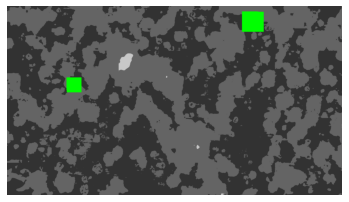

In [21]:
image = Image.open(image_path)
imagedraw = cv2.imread(str(prebubblemaskname))
width, height = image.size
stepsx = (width -640) / 640 * 2 
stepsy = (height-640) / 640 * 2 
x=0 
y=0
it = 1
while (x < stepsx +1) :
    y=0
    while (y<stepsy + 1) : 
        xshift = (0+320*x )  
        yshift = (0+320*y ) 
        
        file_path = here+"/yolov5/runs/detect/bubbledetect/labels/cropimage"+str(it)+".txt"
                                
        try:
            
            data = np.loadtxt(file_path)
            
            dimensions = data.shape
            try:
                notdim = dimensions[1]
                dim = dimensions[0]
            except:
                dim = 1
            row=0 
            
            data = np.vstack((data, data))
            while (row < dim):

                try:

                    row = row +1
                    
                    line = data[row-1]
                    line = line * 640
    

                    # Define the coordinates and size of the rectangle
                    X, Y = int(line[1])+xshift, int(line[2])+yshift  # Top-left corner of the rectangle
                    widthlabel, heightlabel = round(int(line[3])/2), round(int(line[4])/2)  # Width and height of the rectangle

                    # Define the color (BGR format) and thickness of the rectangle
                    color = (0, 255, 0)  # Red color in BGR format (Blue, Green, Red)

                    thickness = -1
                    cv2.rectangle(imagedraw, (X- widthlabel, Y- heightlabel), (X + widthlabel, Y + heightlabel), color, thickness)
                    #print("drawing")
                    # Display the image with the rectangle using matplotlib
                    #plt.imshow(cv2.cvtColor(imagedraw, cv2.COLOR_BGR2RGB))
                    #plt.axis('off')  # Optional: Turn off axis labels
                    #print("draw")
                    #print(it,row)
                except:
                    placeholderorexceptbreaks = 1 
                    #print(it,row)
                    
        except:
            print("no detections")
            print(it)
            placeholderorexceptbreaks = 1 
                

        
        it = it + 1 
        y=y+1
    
    x=x+1
    
    

plt.imshow(cv2.cvtColor(imagedraw, cv2.COLOR_BGR2RGB))
plt.axis('off')  # Optional: Turn off axis labels
plt.show()
pil_image = Image.fromarray(imagedraw)
# Specify the output file path and name
maskfilename = sorted_file_list[imagenumber]
maskfilename = maskfilename.replace("image", "mask")
postbubblemaskname = mainpipelocation+"fullmaskdump/" + maskfilename

from PIL import Image
# Save the image as a PNG file
pil_image.save(postbubblemaskname)

In [ ]:
os.remove(prebubblemaskname)